In [10]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from pathlib import Path
import random
%matplotlib inline 

In [5]:
path = Path("names.txt")

words = path.read_text().splitlines()

print(len(words))
print(words[:10])

32033
['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia', 'harper', 'evelyn']


In [6]:
chs = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chs)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos)

In [8]:
bs = 3

def b_ds(words):
    x, y = [], []
    
    for w in words:
    
        context = [0] * bs
        for ch in w + '.':
            ix = stoi[ch]
            x.append(context)
            y.append(ix)
            context = context[1:] + [ix]
    
    x = torch.tensor(x)
    y = torch.tensor(y)
    return x, y

In [11]:
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

In [12]:
xtrain, ytrain = b_ds(words[:n1])
xval, yval = b_ds(words[n1:n2])
xtest, ytest = b_ds(words[n2:])

In [56]:
# Selected config: {'emb_dim': 24, 'hidden_dim': 750, 'batch_size': 256, 'lr': 0.15355887634905266}
#from the best cfg i found in my last file
n_e = 24
n_h = 750

C = torch.randn((vocab_size, n_e))
w1 = torch.randn((n_e * bs, n_h)) * (5/3) / ((n_e * bs)**.5)
#b1 = torch.randn(n_h) * 0.01
w2 = torch.randn((n_h, vocab_size)) * 0.01
b2 = torch.randn(vocab_size) * 0

bngain = torch.ones((1, n_h))
bnbias = torch.zeros((1, n_h))
bnmean_running = torch.zeros((1, n_h))
bnstd_running = torch.ones((1, n_h))

parameters = [C, w1, b1, w2, b2, bngain, bnbias]

for p in parameters:
    p.requires_grad = True

In [57]:
max_steps = 50000
batch_size = 256
lossi = []
lr = 0.15355887634905266

In [58]:
for i in range(max_steps):

    ix = torch.randint(0, xtrain.shape[0], (batch_size,))
    xb, yb = xtrain[ix], ytrain[ix]

    emb = C[xb]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ w1 #+ b1
    bnmeani = hpreact.mean(0, keepdim=true)
    bnstdi = hpreact.std(0, keepdim=true)
    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias

    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + .001 * bmeani
        bnstd_running = 0.999 * bnstd_running + .001 * bstdi
    
    h = torch.tanh(hpreact)
    logits = h @ w2 + b2
    loss = F.cross_entropy(logits, yb)

    for p in parameters:
        p.grad = None
    loss.backward()

    rate = lr if i < 30001 else lr*0.1
    for p in parameters:
        p.data += -rate * p.grad

    if i % 5000 == 0:
        print (f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

      0/  50000: 3.2993
   5000/  50000: 2.1229
  10000/  50000: 2.0368
  15000/  50000: 2.2699
  20000/  50000: 2.0564
  25000/  50000: 1.9922
  30000/  50000: 1.9291
  35000/  50000: 1.9852
  40000/  50000: 2.0722
  45000/  50000: 1.8501


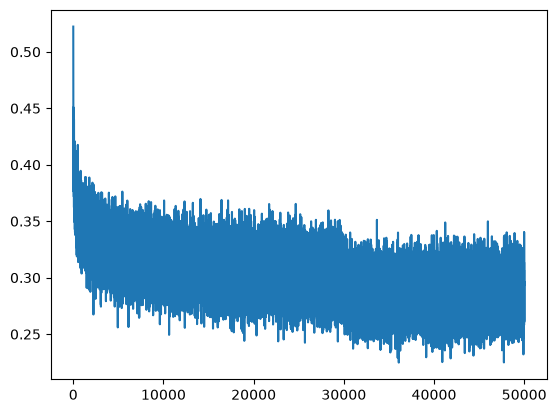

In [54]:
plt.plot(lossi)

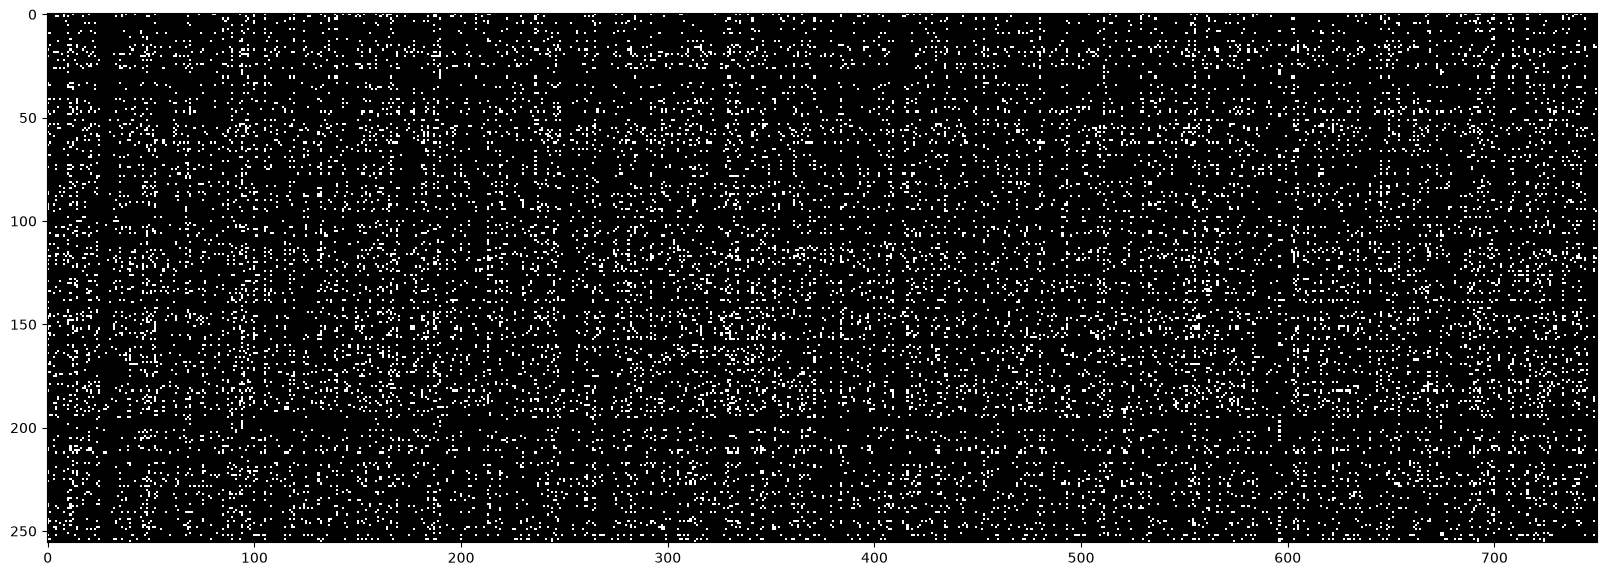

In [30]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation = 'nearest')

In [64]:
@torch.no_grad()

def split_loss(split):
    x, y = {
        'train': (xtrain, ytrain),
        'val' : (xval, yval),
        'test': (xtest, ytest),
    }[split]
    emb = C[x]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ w1 + b1
    hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
    h = torch.tanh(hpreact)
    logits = h @ w2 + b2
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

In [66]:
split_loss('train')
split_loss('val')
split_loss('test')

train 1.9592102766036987
val 2.081624746322632
test 2.0662951469421387


In [61]:
for _ in range(20):

    out = []
    context = [0] * bs
    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(1,-1) @ w1 + b1)
        logits = h @ w2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1).item()
        context = context[1:] + [ix]
        out.append(ix)

        if ix == 0:
            break
    print(''.join(itos[i] for i in out))

dhygzuzlynnlynnavishkyd.
jhovahgamirancyssobashussywgodfriz.
jazmynvertoffiq.
gwyffitzefpyndryxxx.
gabrifulciannavyngregggreggyndradhyadquillph.
gwengstgwaddjywqodryx.
zavrosumpharvid.
jmmykaikmylmoshmungysshrumbbhub.
paxchvyctopppppppppppppppyten.
jockendynisrivladkerrivky.
zzophildingstophingstephyvannvik.
vivotamark.
chdynczulyvonnawhyel.
gwblkspcytrnetteghinchopptggy.
jarvincericklynn.
zygen.
primmykhyynvkadvikrawrynneffanyzebeddyncknyvvangelviktiggdstoprick.
quiah.
xydjusanyriklevernavrencerzygandrkjavinncarmeggsppppppppppprompremmaj.
merggwslamilzeldquinchampik.
